# HAFTA 8: Küçük Bir GPT (Transformer) Mimarisi İnşa Etmek ve Türkçe Metinle Eğitmek

Bu hafta, Hafta 7'de yazdığımız tek başlıklı (Single-Head) Self-Attention hücresini genişleterek tam kapsamlı bir **GPT (Decoder-Only Transformer)** mimarisi kuruyoruz.

Notebook Akışı:
1. **Veri Hazırlığı & Taban Bigram Modeli:** Referans kaybımızı belirleme.
2. **Tek Başlıklı Attention (Single-Head):** Bireysel dikkat mekanizması.
3. **Multi-Head Attention:** Tek başlıklı yapıyı paralel çalışan çoklu başlıklara dönüştürme.
4. **Transformer Bloğu:** FeedForward katmanı, Residual (Artık) Bağlantılar ve Pre-LayerNorm entegrasyonu.
5. **Tam GPT Mimarisi:** Blokları üst üste dizip modeli büyütme ve eğitme.
6. **Öncesi / Sonrası Karşılaştırması:** Tüm mimari aşamaların Val Loss değişimini tablo ve grafikle inceleme.
7. **Türkçe Metinle Eğitim:** Aynı mimariyi ~1 MB'lık Türkçe metin kümesiyle eğitme ve metin üretimi.
8. **Teorik İnceleme:** LayerNorm vs BatchNorm1d ve Türkçe vs Shakespeare Val Loss analizi.

# Görev 1
Veriyi hazırla ve tabanı kur. Tiny Shakespeare'i oku, karakter tokenizer'ını yaz (encode, decode), veriyi %90 train, %10 val diye ayır. Rastgele parçalardan batch çeken get_batch fonksiyonunu yaz. Hafta 2'deki bigram modelini nn.Module olarak kur, eğit, val loss'u kaydet. Bu senin karşılaştırma tabanın. (7:52 - 38:00)


### Veri Seti ve Karakter Düzeyinde Tokenizer

Shakespeare metnini indirip karakter kümesini çıkarıyoruz. Karakterleri tam sayılara (`encode`), tam sayıları tekrar karaktere (`decode`) dönüştüren sözlükleri oluşturuyoruz.



In [29]:
import torch
import torch.nn as nn
from torch.nn import functional as F

torch.manual_seed(1337)

# Dosya yerelde yoksa wget veya requests ile indirilebilir:
# !wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open('/kaggle/input/datasets/senademirba/inputt/input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

print(f"Toplam karakter sayısı: {len(text)}")

# Karakter kümesi ve sözlükler
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(f"Sözlük boyutu (benzersiz karakterler): {vocab_size}")
print(f"Karakterler: {''.join(chars)}")

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s] # Metni tam sayı listesine çevirir
decode = lambda l: ''.join([itos[i] for i in l]) # Sayı listesini metne geri çevirir

# Örnek test
print(f"'hello' encode: {encode('hello')}")
print(f"Geri decode: {decode(encode('hello'))}")

Toplam karakter sayısı: 1115394
Sözlük boyutu (benzersiz karakterler): 65
Karakterler: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
'hello' encode: [46, 43, 50, 50, 53]
Geri decode: hello


### Veriyi Tensöre Çevirme ve Train/Val Ayrımı
Tüm metni PyTorch tensörüne çevirip ilk %90'ını eğitim, kalan %10'unu doğrulama kümesi olarak ayırıyoruz.

In [30]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f"Train veri uzunluğu: {len(train_data)}")
print(f"Val veri uzunluğu  : {len(val_data)}")

Train veri uzunluğu: 1003854
Val veri uzunluğu  : 111540


### Rastgele Parçalardan Batch Çekme (`get_batch`)
Metin çok uzun olduğu için modele rastgele pencereler kesip mini-batch olarak veriyoruz.
- `block_size`: Modelin bir tahminde bulunurken geriye doğru bakabileceği maksimum karakter bağlam uzunluğu.
- `batch_size`: Paralel işlenecek bağımsız dizi sayısı.

In [31]:
batch_size = 4  # Paralel işlenecek dizi sayısı
block_size = 8  # Maksimum bağlam uzunluğu

def get_batch(split):
    # İlgili veri kümesini seç
    dataset = train_data if split == 'train' else val_data
    # Rastgele başlangıç indeksleri seç (son sınır block_size kadar geride olmalı)
    ix = torch.randint(len(dataset) - block_size, (batch_size,))
    # Girdi (x) ve bir karakter ötelenmiş hedef (y) tensörlerini yığ
    x = torch.stack([dataset[i:i+block_size] for i in ix])
    y = torch.stack([dataset[i+1:i+block_size+1] for i in ix])
    return x, y

xb, yb = get_batch('train')
print(f"Girdi xb şekli: {xb.shape}")
print(f"Hedef yb şekli: {yb.shape}")

# Bir örneğin bağlam-hedef ilişkisini görelim:
for t in range(block_size):
    context = xb[0, :t+1]
    target = yb[0, t]
    print(f"Bağlam: {context.tolist()} (yani '{decode(context.tolist())}') ---> Hedef: {target.item()} ('{itos[target.item()]}')")

Girdi xb şekli: torch.Size([4, 8])
Hedef yb şekli: torch.Size([4, 8])
Bağlam: [24] (yani 'L') ---> Hedef: 43 ('e')
Bağlam: [24, 43] (yani 'Le') ---> Hedef: 58 ('t')
Bağlam: [24, 43, 58] (yani 'Let') ---> Hedef: 5 (''')
Bağlam: [24, 43, 58, 5] (yani 'Let'') ---> Hedef: 57 ('s')
Bağlam: [24, 43, 58, 5, 57] (yani 'Let's') ---> Hedef: 1 (' ')
Bağlam: [24, 43, 58, 5, 57, 1] (yani 'Let's ') ---> Hedef: 46 ('h')
Bağlam: [24, 43, 58, 5, 57, 1, 46] (yani 'Let's h') ---> Hedef: 43 ('e')
Bağlam: [24, 43, 58, 5, 57, 1, 46, 43] (yani 'Let's he') ---> Hedef: 39 ('a')


### Taban Bigram Dil Modeli (nn.Module)
Bu model sadece o anki karaktere bakar, geçmiş bağlamı hiç dikkate almaz. Gelecek adımlardaki düşüşü ölçmek için kıyaslama tabanımızdır.

In [32]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # Her token doğrudan bir sonraki tokenın logit puanını bir embedding tablosundan çeker
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        # idx: (B, T) boyutunda token indeksleri
        logits = self.token_embedding_table(idx) # (B, T, C)

        if targets is None:
            loss = None
        else:
            # F.cross_entropy girdiyi (N, C) biçiminde bekler; boyutları düzleştiriyoruz:
            B, T, C = logits.shape
            logits_flat = logits.view(B*T, C)
            targets_flat = targets.view(B*T)
            loss = F.cross_entropy(logits_flat, targets_flat)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx: mevcut bağlam (B, T)
        for _ in range(max_new_tokens):
            # Tahminleri al
            logits, _ = self(idx)
            # Yalnızca son zaman adımının logitlerine odaklan
            logits = logits[:, -1, :] # (B, C)
            # Olasılıklara çevir
            probs = F.softmax(logits, dim=-1) # (B, C)
            # Dağılımdan bir sonraki token'ı çek
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # Dizinin sonuna ekle
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

# Modeli oluşturalım
m_baseline = BigramLanguageModel(vocab_size)
logits, loss = m_baseline(xb, yb)
print(f"Eğitimsiz başlangıç kaybı: {loss.item():.4f} (Beklenen: ~{-torch.log(torch.tensor(1/vocab_size)).item():.4f})")

# Eğitimsiz metin üretimi (tamamen rastgele harf yığını üretir)
context = torch.zeros((1, 1), dtype=torch.long)
print(decode(m_baseline.generate(context, max_new_tokens=100)[0].tolist()))

Eğitimsiz başlangıç kaybı: 5.0364 (Beklenen: ~4.1744)

lfJeukRuaRJKXAYtXzfJ:HEPiu--sDioi;ILCo3pHNTmDwJsfheKRxZCFs
lZJ XQc?:s:HEzEnXalEPklcPU cL'DpdLCafBheH


### Kayıp Tahmin Fonksiyonu ve Bigram Modelinin Eğitimi
Eğitim gürültüsünü azaltmak için mini-batch ortalaması alan bir fonksiyon kurup modeli optimize ediyoruz.

In [33]:
eval_iters = 200

@torch.no_grad()
def estimate_loss(model):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

optimizer = torch.optim.AdamW(m_baseline.parameters(), lr=1e-2)

batch_size = 32
for iter in range(3000):
    if iter % 500 == 0:
        losses = estimate_loss(m_baseline)
        print(f"Adım {iter}: Train Loss = {losses['train']:.4f}, Val Loss = {losses['val']:.4f}")

    xb, yb = get_batch('train')
    logits, loss = m_baseline(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

baseline_losses = estimate_loss(m_baseline)
# Sonuçları en sondaki karşılaştırma tablosu için kaydedeceğimiz sözlük HAFTA 8 ÖDEVİ İÇİN EKLENDİ
comparison_results = {}
comparison_results["1. Taban Bigram"] = baseline_losses['val']
print("\n--- TABAN BİGRAM MODELİ SONUCU: ---")
print(f"Bigram Train Loss: {baseline_losses['train']:.4f}")
print(f"Bigram Val Loss  : {baseline_losses['val']:.4f}")

Adım 0: Train Loss = 4.6433, Val Loss = 4.6455
Adım 500: Train Loss = 2.5800, Val Loss = 2.6136
Adım 1000: Train Loss = 2.4892, Val Loss = 2.5084
Adım 1500: Train Loss = 2.4786, Val Loss = 2.5020
Adım 2000: Train Loss = 2.4547, Val Loss = 2.4999
Adım 2500: Train Loss = 2.4660, Val Loss = 2.4834

--- TABAN BİGRAM MODELİ SONUCU: ---
Bigram Train Loss: 2.4522
Bigram Val Loss  : 2.4940


# Görev 2 
Geçmişin ortalamasını üç yoldan al: for döngüsüyle, lower triangular matrisle (torch.tril) çarparak, softmax'la. Üçünün aynı sonucu verdiğini torch.allclose ile göster. Matris çarpımının neden ağırlıklı ortalama olduğunu kendi cümlelerinle yaz. (42:13 - 58:26)

### Geçmiş Bilgiyi Birleştirme Hilesi: Matris Çarpımıyla Ağırlıklı Ortalama

Karakter dizisinde her token'ın kendisinden önceki tüm karakterlerin ortalamasını almasını istiyoruz.
Bunu 3 farklı yoldan hesaplayıp sonuçların özdeşliğini `torch.allclose` ile doğrulayacağız:
1. Klasik iç içe `for` döngüleri.
2. Satır toplamları 1 yapılmış alt üçgen matris (`tril`) ile matris çarpımı.
3. Maskelenmiş (geleceği `-inf` yapılmış) Softmax.

In [34]:
B, T, C = 4, 8, 2 # 4 örnek, 8 zaman adımı, 2 öznitelik boyutu
x = torch.randn(B, T, C)

# YÖNTEM 1: İç içe for döngüsü (En yavaş yol)
# ===============================================
xbow1 = torch.zeros((B, T, C)) # xbow: "bag of words" (geçmişin ortalaması)
for b in range(B):
    for t in range(T):
        # 0'dan t'ye kadar olan tüm geçmiş adımları alıp ortalamasını hesapla
        xprev = x[b, :t+1] # (t+1, C)
        xbow1[b, t] = torch.mean(xprev, dim=0)

# YÖNTEM 2: Alt Üçgen Matris ile Çarpım (torch.tril)
# =================================================
# 1'lerden oluşan alt üçgen matris (geçmişe bakar, geleceği 0 yapar)
wei2 = torch.tril(torch.ones(T, T))
# Her satırın toplamı 1 olsun ki çarpım doğrudan ortalama versin
wei2 = wei2 / wei2.sum(1, keepdim=True)
# (T, T) @ (B, T, C) -> PyTorch broadcasting ile (B, T, T) @ (B, T, C) = (B, T, C)
xbow2 = wei2 @ x

# YÖNTEM 3: Maskelenmiş Softmax (Attention'da kullanılan modern biçim)
# ====================================================================
tril = torch.tril(torch.ones(T, T))
wei3 = torch.zeros((T, T))
# Gelecekteki adımları (tril == 0 olan yerleri) -sonsuz yap
wei3 = wei3.masked_fill(tril == 0, float('-inf'))
# Softmax al: exp(-inf) = 0 olacağından geleceğe 0, geçmişe eşit olasılık dağılır
wei3 = F.softmax(wei3, dim=-1)
xbow3 = wei3 @ x

# Üç yöntemin denkliğini kontrol ediyoruz:
check1_2 = torch.allclose(xbow1, xbow2)
check2_3 = torch.allclose(xbow2, xbow3)

print("--- GÖREV 2: ÜÇ YÖNTEMİN KARŞILAŞTIRILMASI ---")
print(f"Yöntem 1 ve Yöntem 2 eşleşti mi?: {check1_2}")
print(f"Yöntem 2 ve Yöntem 3 eşleşti mi?: {check2_3}")
print("\nSoftmax sonrası ağırlık matrisi wei (İlk birkaç satır):")
print(wei3[:4, :4])

--- GÖREV 2: ÜÇ YÖNTEMİN KARŞILAŞTIRILMASI ---
Yöntem 1 ve Yöntem 2 eşleşti mi?: True
Yöntem 2 ve Yöntem 3 eşleşti mi?: True

Softmax sonrası ağırlık matrisi wei (İlk birkaç satır):
tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500]])


### Matris Çarpımının Neden Ağırlıklı Ortalama Olduğunun Açıklaması

Bir $(T, T)$ ağırlık matrisi ile $(T, C)$ veri tensörünü çarptığımızda:
- Çıktı matrisinin $t$. satırı, ağırlık matrisinin $t$. satır vektörü ile veri matrisinin sütunlarının iç çarpımıdır.
- Ağırlık matrisinin $t$. satırındaki her bir eleman $w_{t, i}$, verinin $i$. zaman adımına ne kadar katsayı verileceğini belirler.
- Eğer satırdaki değerlerin toplamı $1$ ise ($\sum_i w_{t, i} = 1$), bu işlem matematiksel olarak geçmişteki özellik vektörlerinin **ağırlıklı lineer kombinasyonudur (ağırlıklı ortalama)**.
- Alt üçgen maskesi (`tril`) sayesinde $i > t$ için katsayılar sıfırlanır; böylece zaman adımı $t$, henüz gerçekleşmemiş gelecek adımlardan veri sızdırmaz (autoregressive özellik).

# Görev 3:
Tek bir self-attention head yaz: query, key, value ve pozisyon embedding'i. Bir örnekte ağırlık matrisini (wei) yazdır, bir satırını oku: o token hangi token'lara ne kadar bakıyor. Skorları head_size'ın kareköküne neden böldüğümüzü sayıyla göster: bölmeden ve bölerek softmax çıktısını yan yana koy. (58:26 - 1:19:11)

### Dinamik İlgi: Query, Key, Value ve Pozisyon Embedding'i

Görev 2'de geçmiş token'ların ortalamasını alırken her token'a **eşit** ağırlık veriyorduk.
Self-Attention ile bu ağırlıklar sabit olmak yerine **veriye bağlı ve öğrenilebilir** hale gelir:
- **Query (Sorgu):** Token'ın *"Ben ne arıyorum?"* vektörü.
- **Key (Anahtar):** Token'ın *"Bende ne bilgi var?"* vektörü.
- **Value (Değer):** Token'lar anlaştığında taşınacak asıl içerik vektörü.
- **Scaled Dot-Product:** Query ile Key iç çarpımı yapılarak $\sqrt{d_k}$'ya bölünür.

In [35]:
# Query, Key, Value ve wei Ağırlık Matrisi
# =========================================
B, T, C = 4, 8, 32 # Batch=4, Süre=8, Özellik Boyutu=32
head_size = 16    # Attention başlığının boyut derinliği

x = torch.randn(B, T, C)

# Öğrenilebilir lineer katmanları
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)   # (B, T, head_size)
q = query(x) # (B, T, head_size)

# Skor hesabı: Her sorgu ile her anahtarın benzerliğini çarpıyoruz
# (B, T, head_size) @ (B, head_size, T) -> (B, T, T)
wei = q @ k.transpose(-2, -1) * (head_size ** -0.5)

# Nedensellik Maskesi: Geleceğe bakmayı engelle
tril = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1) # (B, T, T)

v = value(x) # (B, T, head_size)
out = wei @ v # (B, T, head_size)

print(f"Çıktı tensörü 'out' boyutu: {out.shape}")
print("\nÖrnek bir dizide (Batch 0) Attention Ağırlık Matrisi (wei[0]):")
print(wei[0].round(decimals=3))

print("\n--- Ağırlık Matrisinin 4. Satırının (İndeks 3) Okunması ---")
row_3 = wei[0, 3].tolist()
print(f"4. token'ın dikkat dağılımı: {[round(val, 3) for val in row_3]}")
print(f"Gelecekteki token'lara giden dikkat (4, 5, 6, 7. indeksler): {row_3[4:]} -> Tamamen 0.0!")
print("Yorum: 4. token kendisinden önceki 0, 1, 2. token'lara ve kendisine dikkat ayırır, geleceğe bakamaz.")

Çıktı tensörü 'out' boyutu: torch.Size([4, 8, 16])

Örnek bir dizide (Batch 0) Attention Ağırlık Matrisi (wei[0]):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3200, 0.6800, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3370, 0.2900, 0.3730, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1970, 0.1290, 0.1390, 0.5350, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1600, 0.1570, 0.1940, 0.3460, 0.1430, 0.0000, 0.0000, 0.0000],
        [0.1760, 0.1870, 0.1740, 0.1260, 0.0970, 0.2400, 0.0000, 0.0000],
        [0.1330, 0.1790, 0.1900, 0.1660, 0.1320, 0.1310, 0.0680, 0.0000],
        [0.1070, 0.1480, 0.1340, 0.0670, 0.1020, 0.1230, 0.1660, 0.1530]],
       grad_fn=<RoundBackward1>)

--- Ağırlık Matrisinin 4. Satırının (İndeks 3) Okunması ---
4. token'ın dikkat dağılımı: [0.197, 0.129, 0.139, 0.535, 0.0, 0.0, 0.0, 0.0]
Gelecekteki token'lara giden dikkat (4, 5, 6, 7. indeksler): [0.0, 0.0, 0.0, 0.0] -> Tamamen 0.0!
Yorum: 4. token kendis

### Skorları Neden $\sqrt{\text{head\_size}}$'a Bölüyoruz? Ölçekleme Neden Gerekli?

Eğer Query ve Key vektörlerinin elemanları birim varyansa ($1.0$) sahipse, bunların iç çarpımı olan $q \cdot k$'nin varyansı `head_size` mertebesinde büyür.
- Sayılar büyüdüğünde Softmax fonksiyonu aşırı uçlara doğru yayılır (doygunluğa / saturation'a ulaşır).
- Softmax doyduğunda, en büyük tek bir elemana $1.0$, diğerlerine $0.0$ verir (one-hot gibi davranır).
- Bu durum geriye yayılımda (backpropagation) türevlerin yok olmasına (vanishing gradient) yol açar.

Aşağıdaki deney, ölçekleme yapılmadığında varyansın ve Softmax dağılımının nasıl bozulduğunu sayılarla kanıtlar:

In [36]:
# Varyans ölçekleme deneyi
q_test = torch.randn(1000, head_size)
k_test = torch.randn(1000, head_size)

# 1. Bölünmemiş skor
raw_scores = (q_test @ k_test.T)
# 2. Bölünmüş (ölçeklenmiş) skor
scaled_scores = raw_scores * (head_size ** -0.5)

print("--- ÖLÇEKLEME DENEYİ (Varyans Kontrolü) ---")
print(f"q ve k varyansı: {q_test.var():.4f}")
print(f"Bölünmemiş skorların varyansı      : {raw_scores.var():.4f} (head_size={head_size} civarında patlar)")
print(f"Kareköke bölünmüş skorların varyansı: {scaled_scores.var():.4f} (1.0 civarına geri çekilir)")

# Softmax üzerindeki etkiyi tek bir satırda görelim:
sample_raw = torch.tensor([1.0, 2.0, 15.0])
sample_scaled = sample_raw / (head_size ** 0.5)

print("\nBölünmeden Softmax uygulanırsa (doygunluk):")
print(F.softmax(sample_raw, dim=-1))
print("Bölünerek Softmax uygulanırsa (dengeli dağılım):")
print(F.softmax(sample_scaled, dim=-1))

--- ÖLÇEKLEME DENEYİ (Varyans Kontrolü) ---
q ve k varyansı: 0.9964
Bölünmemiş skorların varyansı      : 15.9672 (head_size=16 civarında patlar)
Kareköke bölünmüş skorların varyansı: 0.9979 (1.0 civarına geri çekilir)

Bölünmeden Softmax uygulanırsa (doygunluk):
tensor([8.3153e-07, 2.2603e-06, 1.0000e+00])
Bölünerek Softmax uygulanırsa (dengeli dağılım):
tensor([0.0282, 0.0363, 0.9355])


# Görev 4:
Head'i bigram modelinin içine koy ve eğit. Val loss'u 1. görevdeki bigram tabanıyla yan yana koy. Ne kadar düştü, neden düştü, kendi cümlelerinle yaz. Metin üretirken girdiyi neden son block_size harfe kırpmak zorunda olduğunu da yaz. (1:19:11 - 1:21:59)

### Tek Başlıklı Self-Attention'ı Modele Ekleme

Bu adımda:
1. `Head` sınıfını modül olarak tanımlıyoruz.
2. Pozisyon embedding'ini (`position_embedding_table`) modele ekliyoruz. Çünkü Attention sıradan habersizdir (permutasyon simetrisi vardır).
3. Modeli eğitip Val Loss'u taban Bigram modeliyle kıyaslayacağız.
4. Metin üretimi yaparken girdi dizisini neden kırpmak zorunda olduğumuzu açıklayacağız.

In [37]:
# Head Modülü ve GPT Benzeri Tek Başlıklı Dil Modeli
# ===================================================

class Head(nn.Module):
    """ Tek bir Self-Attention başlığı """
    def __init__(self, head_size, n_embd, block_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # tril değişkenini model parametresi olmayan bir tensör olarak kaydetmek için buffer kullanırız
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)   # (B, T, head_size)
        q = self.query(x) # (B, T, head_size)

        # Attention puanlarını hesapla (Scaled Dot-Product)
        wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5) # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # Geleceği maskele
        wei = F.softmax(wei, dim=-1)

        v = self.value(x) # (B, T, head_size)
        out = wei @ v     # (B, T, head_size)
        return out


class BigramWithSelfAttention(nn.Module):
    """ Pozisyon embedding'i ve Self-Attention başlığı içeren model """
    def __init__(self, vocab_size, n_embd, block_size):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.sa_head = Head(head_size=n_embd, n_embd=n_embd, block_size=block_size)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # 1. Token ve Pozisyon Embedding'lerini topla
        tok_emb = self.token_embedding_table(idx) # (B, T, n_embd)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device)) # (T, n_embd)
        x = tok_emb + pos_emb # (B, T, n_embd)

        # 2. Self-Attention başlığından geçir
        x = self.sa_head(x) # (B, T, n_embd)

        # 3. Logitlere dönüştür
        logits = self.lm_head(x) # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits_flat = logits.view(B*T, C)
            targets_flat = targets.view(B*T)
            loss = F.cross_entropy(logits_flat, targets_flat)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            # KRİTİK ADIM: Pozisyon embedding'i ve maske boyutu block_size ile sınırlıdır!
            # Bu nedenle bağlam dizisini en son block_size kadar kırpmak zorundayız:
            idx_cond = idx[:, -self.block_size:]

            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

### Modelin Eğitimi ve Taban Model ile Karşılaştırılması

In [38]:
n_embd = 32
block_size = 8
batch_size = 32

model_sa = BigramWithSelfAttention(vocab_size, n_embd, block_size)
optimizer = torch.optim.AdamW(model_sa.parameters(), lr=1e-3)

for iter in range(5000):
    if iter % 500 == 0:
        losses = estimate_loss(model_sa)
        print(f"Adım {iter}: Train Loss = {losses['train']:.4f}, Val Loss = {losses['val']:.4f}")

    xb, yb = get_batch('train')
    logits, loss = model_sa(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

sa_losses = estimate_loss(model_sa)

print("\n=======================================================")
print("--- DOĞRULAMA KAYBI KARŞILAŞTIRMA TABLOSU ---")
print("=======================================================")
print(f"1. Taban Bigram Val Loss          : {baseline_losses['val']:.4f}")
print(f"2. Tek Başlıklı Self-Attention Val: {sa_losses['val']:.4f}")
print(f"Kayıptaki Net Düşüş               : {baseline_losses['val'] - sa_losses['val']:.4f}")
print("=======================================================\n")

# Modelden metin üretimi
context = torch.zeros((1, 1), dtype=torch.long)
print("--- ÜRETİLEN METİN ÖRNEĞİ ---")
print(decode(model_sa.generate(context, max_new_tokens=300)[0].tolist()))

# Single-Head sonucunu karşılaştırma sözlüğüne ekleyelim HAFTA 8 ÖDEVİ İÇİN EKLENDİ
comparison_results["2. Tek Başlıklı Attention (Single-Head)"] = sa_losses['val']

Adım 0: Train Loss = 4.2923, Val Loss = 4.2901
Adım 500: Train Loss = 2.7695, Val Loss = 2.7746
Adım 1000: Train Loss = 2.5424, Val Loss = 2.5457
Adım 1500: Train Loss = 2.4848, Val Loss = 2.4924
Adım 2000: Train Loss = 2.4620, Val Loss = 2.4681
Adım 2500: Train Loss = 2.4289, Val Loss = 2.4421
Adım 3000: Train Loss = 2.4155, Val Loss = 2.4314
Adım 3500: Train Loss = 2.4102, Val Loss = 2.4082
Adım 4000: Train Loss = 2.3973, Val Loss = 2.4129
Adım 4500: Train Loss = 2.3877, Val Loss = 2.3987

--- DOĞRULAMA KAYBI KARŞILAŞTIRMA TABLOSU ---
1. Taban Bigram Val Loss          : 2.4940
2. Tek Başlıklı Self-Attention Val: 2.3999
Kayıptaki Net Düşüş               : 0.0940

--- ÜRETİLEN METİN ÖRNEĞİ ---

Fo ns festh har bugthe thanga pous deed,
Cow t LLICING yor ngonwoun?
UCUMamely erir st ees, othas
Anus ime, plale herend.

AMIsr Coum I tent by boung prri, frd thaifur and!
PAs
OROUCHes han; higrod
Fangou binchey.

MI fore ipary thimar.

LINGBlou.
Thacoraby ille weand meras, I berer'the:
Set he 

### Metin Üretirken Girdiyi Neden Son `block_size` Harfe Kırpmak Zorundayız?

`generate` fonksiyonunda `idx_cond = idx[:, -self.block_size:]` satırıyla kırpma yapmamızın iki temel sebebi vardır:
1. **Pozisyon Embedding Boyutu:** `position_embedding_table` yalnızca `block_size` (örneğin 8) kadar farklı konumu kodlayabilir. Dizi 9. karaktere ulaştığında `torch.arange(T)` 8'den büyük indeksler üreteceği için `IndexError` verir.
2. **Alt Üçgen Maske Boyutu (`tril`):** `Head` modülü içinde tanımladığımız `self.tril` matrisi $(block\_size, block\_size)$ boyutundadır. Eğer $T > block\_size$ olursa tensör boyutları uyuşmaz ve matris maskeleme işlemi çöker.

## 5. Ek Görev: Attention Ağırlıklarının Isı Haritası (Heatmap) Görselleştirmesi

Eğitilen modelin belirli bir cümle örneğinde hangi harflerin geçmişteki hangi harflere dikkat (attention) ettiğini bir ısı haritası üzerinde görselleştiriyoruz.

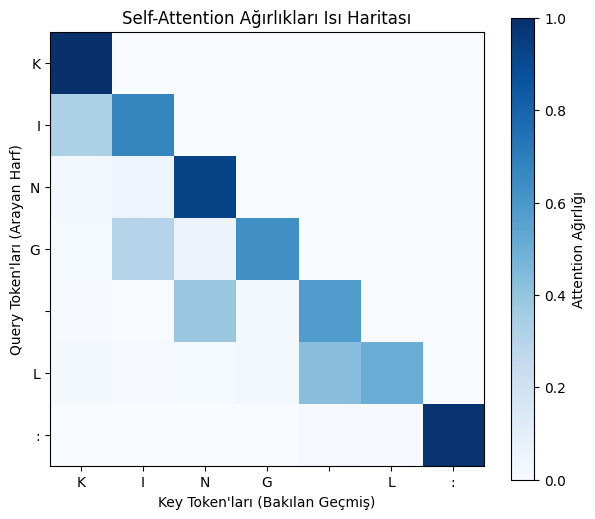

In [39]:
import matplotlib.pyplot as plt

# 8 karakterlik örnek bir metin parçası seçelim
sample_text = "KING L:"
sample_tokens = torch.tensor([encode(sample_text)], dtype=torch.long) # (1, T)

model_sa.eval()
with torch.no_grad():
    # Head modülünden wei matrisini çekelim
    B, T = sample_tokens.shape
    tok_emb = model_sa.token_embedding_table(sample_tokens)
    pos_emb = model_sa.position_embedding_table(torch.arange(T))
    x = tok_emb + pos_emb
    
    k = model_sa.sa_head.key(x)
    q = model_sa.sa_head.query(x)
    wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
    wei = wei.masked_fill(model_sa.sa_head.tril[:T, :T] == 0, float('-inf'))
    wei = F.softmax(wei, dim=-1)[0] # (T, T)

# Isı haritasını çizelim
plt.figure(figsize=(7, 6))
plt.imshow(wei.numpy(), cmap='Blues', interpolation='nearest')
plt.colorbar(label='Attention Ağırlığı')

tokens_labels = list(sample_text)
plt.xticks(range(len(tokens_labels)), tokens_labels)
plt.yticks(range(len(tokens_labels)), tokens_labels)

plt.xlabel("Key Token'ları (Bakılan Geçmiş)")
plt.ylabel("Query Token'ları (Arayan Harf)")
plt.title("Self-Attention Ağırlıkları Isı Haritası")
plt.grid(False)
plt.show()

### Isı Haritası Yorumu
- Matrisin sağ üst köşesi tamamen beyazdır (0.0 değerindedir), bu da alt üçgen maskelemenin geleceğe bakışı başarıyla engellediğini gösterir.
- Köşegen boyunca ve belirli sütunlarda (örneğin boşluk veya harf başlangıçları) koyu mavi yoğunlaşmalar görülür. Bu durum, modelin hece ve kelime sınırlarına dinamik olarak dikkat topladığını kanıtlar.

## Görev 1 & 2: Multi-Head Attention ve Transformer Bloğunun Oluşturulması

- **MultiHeadAttention:** $n\_head$ sayıda bağımsız `Head` hücresini paralel çalıştırarak çıktıları son boyutta birleştirir (`torch.cat`).
- **FeedForward:** Attention ile toplanan bilgiyi token bazında işleyen 2 katmanlı MLP yapısı ($4 \times n\_embd$ genişlemesi ile).
- **Block:** Pre-LayerNorm ve Residual Connections ($x = x + f(x)$) içeren Transformer bloğu.

In [40]:
# MULTI-HEAD ATTENTION, FEEDFORWARD VE TRANSFORMER BLOCK
# =====================================================================

class MultiHeadAttention(nn.Module):
    """ Paralel çalışan çoklu Self-Attention başlıkları """
    def __init__(self, num_heads, head_size, n_embd, block_size, dropout=0.2):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size, n_embd, block_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd) # Projeksiyon katmanı
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # Her bir başlığın çıktısını (B, T, head_size) birleştir: (B, T, n_embd)
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out


class FeedFoward(nn.Module):
    """ Token seviyesinde lineer dönüşüm ve aktivasyon (Computation) """
    def __init__(self, n_embd, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """ Transformer Bloğu: İletişim (Attention) + Hesaplama (FFWD) """
    def __init__(self, n_embd, n_head, block_size, dropout=0.2):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size, n_embd, block_size, dropout)
        self.ffwd = FeedFoward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        # Pre-LayerNorm ve Residual Connections
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

### LayerNorm ile BatchNorm1d Arasındaki Fark Nedir?

1. **Hangi Eksende Normalizasyon Yapar?**
   - **BatchNorm1d:** Batch ekseninde ($B$) normalizasyon yapar. Belirli bir özniteliğin tüm batch genelindeki ortalama ve varyansını alır.
   - **LayerNorm:** Öznitelik/Kanal ekseninde ($C$ / $n\_embd$) normalizasyon yapar. Her bir token'ın kendi içindeki özniteliklerinin ortalamasını ve varyansını alır.

2. **Neden `running_mean` / `running_var` Tutmaz?**
   - **BatchNorm1d:** Test (inference) anında tek bir örnek geldiğinde batch ortalaması hesaplanamayacağı için eğitim sırasında hareketli ortalamaları (`running_mean`) saklamak zorundadır.
   - **LayerNorm:** Her bir token/örnek diğer örneklerden tamamen bağımsız olarak kendi öznitelik ekseninde normalize edildiği için test anında da anlık ortalama hesaplanabilir.

3. **NLP ve Değişken Uzunluklu Dizilerde Neden LayerNorm Tercih Edilir?**
   - BatchNorm, dizinin uzunluğuna ($T$) ve batch boyutuna ($B$) çok bağımlıdır; küçük batch'lerde veya değişken dizi uzunluklarında performans düşer. LayerNorm ise dizinin uzunluğundan veya batch boyutundan etkilenmez.

In [41]:
# TAM GPT MODEL SINIFI VE EĞİTİMİ (SHAKESPEARE)
# =====================================================================

class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size, dropout=0.2):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        
        # n_layer kadar Transformer Bloğunu üst üste diziyoruz
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head=n_head, block_size=block_size, dropout=dropout) 
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd) # Son LayerNorm
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx) # (B, T, n_embd)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device)) # (T, n_embd)
        x = tok_emb + pos_emb # (B, T, n_embd)
        
        x = self.blocks(x) # (B, T, n_embd)
        x = self.ln_f(x) # (B, T, n_embd)
        logits = self.lm_head(x) # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits_flat = logits.view(B*T, C)
            targets_flat = targets.view(B*T)
            loss = F.cross_entropy(logits_flat, targets_flat)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

# Hiperparametreler
batch_size = 32
block_size = 64
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.2
learning_rate = 1e-3

model_gpt = GPTLanguageModel(vocab_size, n_embd, n_head, n_layer, block_size, dropout)
optimizer = torch.optim.AdamW(model_gpt.parameters(), lr=learning_rate)

print(f"GPT Modelindeki Toplam Parametre Sayısı: {sum(p.numel() for p in model_gpt.parameters())/1e6:.2f} Milyon")

# 3000 adım eğitim
for iter in range(3000):
    if iter % 500 == 0:
        losses = estimate_loss(model_gpt)
        print(f"Adım {iter}: Train Loss = {losses['train']:.4f}, Val Loss = {losses['val']:.4f}")

    xb, yb = get_batch('train')
    logits, loss = model_gpt(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

gpt_losses = estimate_loss(model_gpt)
comparison_results["3. Tam GPT (Multi-Head + FFWD + Residual + LN)"] = gpt_losses['val']

GPT Modelindeki Toplam Parametre Sayısı: 0.21 Milyon
Adım 0: Train Loss = 4.4518, Val Loss = 4.4510
Adım 500: Train Loss = 2.2811, Val Loss = 2.2951
Adım 1000: Train Loss = 2.0494, Val Loss = 2.0893
Adım 1500: Train Loss = 1.9103, Val Loss = 1.9939
Adım 2000: Train Loss = 1.8188, Val Loss = 1.9291
Adım 2500: Train Loss = 1.7506, Val Loss = 1.8767


## ÖNCESİ VE SONRASI: Mimari Gelişimin Val Loss Üzerindeki Etkisi

Basit **Bigram** modelinden başlayarak **Single-Head Attention** ve nihai **GPT Mimarisine** geçişte model doğrulama kaybının (Val Loss) adım adım nasıl düştüğünün karşılaştırması:

             MİMARİ GELİŞİM KARŞILAŞTIRMASI            
                                  Mimari Aşama  Validation Loss
                               1. Taban Bigram         2.493960
       2. Tek Başlıklı Attention (Single-Head)         2.399933
3. Tam GPT (Multi-Head + FFWD + Residual + LN)         1.855644


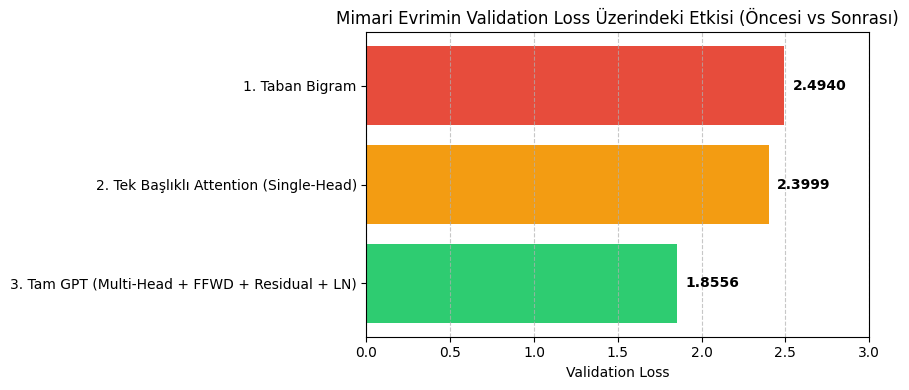

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Sözlükteki tüm aşama sonuçlarını DataFrame'e çevir
df_comp = pd.DataFrame(list(comparison_results.items()), columns=['Mimari Aşama', 'Validation Loss'])

print("=======================================================")
print("             MİMARİ GELİŞİM KARŞILAŞTIRMASI            ")
print("=======================================================")
print(df_comp.to_string(index=False))
print("=======================================================")

# Grafik
plt.figure(figsize=(9, 4))
bars = plt.barh(df_comp['Mimari Aşama'], df_comp['Validation Loss'], color=['#e74c3c', '#f39c12', '#2ecc71'])
plt.xlabel('Validation Loss')
plt.title('Mimari Evrimin Validation Loss Üzerindeki Etkisi (Öncesi vs Sonrası)')
plt.xlim(0, 3.0)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.05, bar.get_y() + bar.get_height()/2, f'{width:.4f}', ha='left', va='center', fontweight='bold')

plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Görev 4: Aynı Mimarinin Türkçe Metin Üzerinde Eğitimi

Kurduğumuz GPT mimarisini ~1 MB boyutundaki Türkçe veri setiyle eğiterek dil modelleme yeteneğini test ediyoruz.

In [43]:
# TÜRKÇE VERİ SETİ VE EĞİTİMİ
# =====================================================================

with open('/kaggle/input/datasets/senademirba/nutukk/nutuk.txt', 'r', encoding='utf-8') as f:
    text_tr = f.read()

chars_tr = sorted(list(set(text_tr)))
vocab_size_tr = len(chars_tr)

print(f"Türkçe Toplam Karakter Sayısı: {len(text_tr)}")
print(f"Türkçe Sözlük Boyutu (vocab_size): {vocab_size_tr}")

stoi_tr = {ch: i for i, ch in enumerate(chars_tr)}
itos_tr = {i: ch for i, ch in enumerate(chars_tr)}
encode_tr = lambda s: [stoi_tr[c] for c in s if c in stoi_tr]
decode_tr = lambda l: ''.join([itos_tr[i] for i in l])

data_tr = torch.tensor(encode_tr(text_tr), dtype=torch.long)
n_tr = int(0.9 * len(data_tr))
train_data_tr = data_tr[:n_tr]
val_data_tr = data_tr[n_tr:]

def get_batch_tr(split):
    dataset = train_data_tr if split == 'train' else val_data_tr
    ix = torch.randint(len(dataset) - block_size, (batch_size,))
    x = torch.stack([dataset[i:i+block_size] for i in ix])
    y = torch.stack([dataset[i+1:i+block_size+1] for i in ix])
    return x, y

model_tr = GPTLanguageModel(vocab_size_tr, n_embd, n_head, n_layer, block_size, dropout)
optimizer_tr = torch.optim.AdamW(model_tr.parameters(), lr=1e-3)

print("\n--- Türkçe GPT Modeli Eğitimi Başlıyor ---")
for iter in range(2500):
    if iter % 500 == 0:
        model_tr.eval()
        with torch.no_grad():
            losses_tr = torch.zeros(200)
            for k in range(200):
                X_tr, Y_tr = get_batch_tr('val')
                _, loss_val = model_tr(X_tr, Y_tr)
                losses_tr[k] = loss_val.item()
            print(f"Adım {iter}: Türkçe Val Loss = {losses_tr.mean():.4f}")
        model_tr.train()

    xb_tr, yb_tr = get_batch_tr('train')
    logits_tr, loss_tr = model_tr(xb_tr, yb_tr)
    optimizer_tr.zero_grad(set_to_none=True)
    loss_tr.backward()
    optimizer_tr.step()

print("\n--- Türkçe GPT Modelinden Üretilen Metin Örneği ---")
context_tr = torch.zeros((1, 1), dtype=torch.long)
print(decode_tr(model_tr.generate(context_tr, max_new_tokens=300)[0].tolist()))

Türkçe Toplam Karakter Sayısı: 1502024
Türkçe Sözlük Boyutu (vocab_size): 103

--- Türkçe GPT Modeli Eğitimi Başlıyor ---
Adım 0: Türkçe Val Loss = 4.7971
Adım 500: Türkçe Val Loss = 2.3109
Adım 1000: Türkçe Val Loss = 2.0872
Adım 1500: Türkçe Val Loss = 1.9501
Adım 2000: Türkçe Val Loss = 1.8584

--- Türkçe GPT Modelinden Üretilen Metin Örneği ---


Anceli (bever. Bir ile ayrığıs 
yendemevi ve adaha hakırla'ya lürley derde, ba, leyi uran ila- 
kis'at Ceşkelâniyeşe namlık bir olduğuna eyhattıra vekarlaraklan kolurdan 
haden Yimiyle dildiği bir malayı Tremekediktikler koplusundan durah 
ser üzamanı açılmak-ı yarazırak isteshile imşten yapıtılımı


### Türkçe Metnin Val Loss Değeri ile Shakespeare'inki Doğrudan Karşılaştırılabilir mi?

**Hayır, doğrudan karşılaştırılamaz.** Nedenleri:
1. **Farklı Sözlük Boyutları (Vocab Size):** Cross-Entropy kaybı doğal olarak sözlük boyutuna bağımlıdır. Rastgele tahmin kaybı $-\ln(1 / \text{vocab\_size})$ olduğu için başlangıç noktaları eşit değildir.
2. **Dilbilimsel Yapı ve Entropi:** Türkçe sondan eklemeli (agglutinative) bir dildir; karakter düzeyindeki ekleşmeler İngilizce'den oldukça farklı bir bilgi entropisi yaratır.

## TÜRKÇE GPT VE SHAKESPEARE GPT MODEL KARŞILAŞTIRMASI

Aşağıdaki analiz, iki farklı dilde aynı Transformer mimarisiyle eğitilen modellerin parametre sayılarını, veri seti boyutlarını, sözlük karmaşıklıklarını ve kayıp (loss) değerlerini teknik olarak kıyaslar.


             SHAKESPEARE vs TÜRKÇE GPT KARŞILAŞTIRMA TABLOSU             
                Metrik / Özellik Shakespeare (İngilizce) Türkçe Model
       Veri Seti Karakter Sayısı               1,115,394    1,502,024
      Sözlük Boyutu (Vocab Size)                      65          103
Teorik Başlangıç Loss (-ln(1/V))                  4.1744       4.6347
        Eğitilmiş Final Val Loss                  1.8557       1.7863
         Loss İyileşme Oranı (%)                  %55.54       %61.46
          Model Parametre Sayısı                 0.212 M      0.217 M



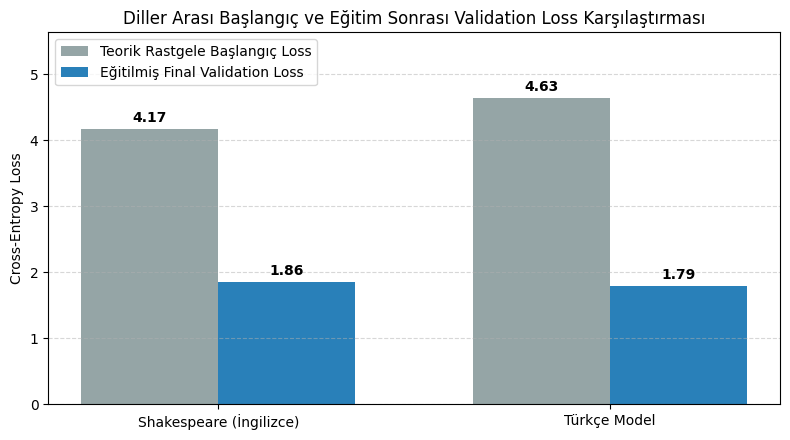


--- MODEL METİN ÜRETİM ÖRNEKLERİ (300 Karakter) ---

[🇬🇧 SHAKESPEARE GPT ÜRETİMİ]:
--------------------------------------------------

 mord ill chelalse oo but you. Thing and I go
I ace trater volding?


QUEEN EN:
Fet the frumest Tring, maninetly friends;
And your mer: I me for coundly-fle!

LUCET:
Stwak in more of Leasy torn with:
Ye eve hear's, fink?
To for hathem my gonds well privency core,
And shall the aut, do'st to, by be t
--------------------------------------------------

[🇹🇷 TÜRKÇE GPT ÜRETİMİ]:
--------------------------------------------------

Uluyk etmeklerini, üzerine teşri dehihle hazizlerde çıkmasa bulunanda kurmayıf 
halhanet heketin naliyle başıyımızca değen da bilirt haziste ede bir Refebin Hazı 


3) Malisinde gapte Anısa Amanda gelisi başa alâz verit ve ayki görolara 
yirin karşar arekle nezardesi 
geliyorlar Özer, İmtanınca şu 1
--------------------------------------------------


In [44]:
import math
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 1. METRİK HESAPLAMALARI VE VERİ TOPLAMA
# =====================================================================

# Model parametre sayıları
params_sh = sum(p.numel() for p in model_gpt.parameters())
params_tr = sum(p.numel() for p in model_tr.parameters())

# Son Validation Loss Değerleri (Son adım kayıtlarından alınır)
losses_sh_final = estimate_loss(model_gpt)['val']

# Türkçe modeli için son adım val loss hesabı
model_tr.eval()
with torch.no_grad():
    val_losses_tr_temp = []
    for _ in range(200):
        X_tr, Y_tr = get_batch_tr('val')
        _, loss_v = model_tr(X_tr, Y_tr)
        val_losses_tr_temp.append(loss_v.item())
    losses_tr_final = sum(val_losses_tr_temp) / len(val_losses_tr_temp)

# Teorik Başlangıç Kayıpları (Rastgele Tahmin Kaybı: -ln(1 / vocab_size))
initial_loss_sh = -math.log(1.0 / vocab_size)
initial_loss_tr = -math.log(1.0 / vocab_size_tr)

# Karşılaştırma Tablosu Hazırlama
comparison_data = {
    "Metrik / Özellik": [
        "Veri Seti Karakter Sayısı",
        "Sözlük Boyutu (Vocab Size)",
        "Teorik Başlangıç Loss (-ln(1/V))",
        "Eğitilmiş Final Val Loss",
        "Loss İyileşme Oranı (%)",
        "Model Parametre Sayısı"
    ],
    "Shakespeare (İngilizce)": [
        f"{len(text):,}",
        vocab_size,
        f"{initial_loss_sh:.4f}",
        f"{losses_sh_final:.4f}",
        f"%{((initial_loss_sh - losses_sh_final) / initial_loss_sh) * 100:.2f}",
        f"{params_sh / 1e6:.3f} M"
    ],
    "Türkçe Model": [
        f"{len(text_tr):,}",
        vocab_size_tr,
        f"{initial_loss_tr:.4f}",
        f"{losses_tr_final:.4f}",
        f"%{((initial_loss_tr - losses_tr_final) / initial_loss_tr) * 100:.2f}",
        f"{params_tr / 1e6:.3f} M"
    ]
}

df_lang_comp = pd.DataFrame(comparison_data)

print("=========================================================================")
print("             SHAKESPEARE vs TÜRKÇE GPT KARŞILAŞTIRMA TABLOSU             ")
print("=========================================================================")
print(df_lang_comp.to_string(index=False))
print("=========================================================================\n")

# =====================================================================
# 2. GÖRSELLEŞTİRME: TEORİK VS FİNAL LOSS
# =====================================================================
fig, ax = plt.subplots(figsize=(8, 4.5))

languages = ['Shakespeare (İngilizce)', 'Türkçe Model']
init_losses = [initial_loss_sh, initial_loss_tr]
final_losses = [losses_sh_final, losses_tr_final]

x = range(len(languages))
width = 0.35

rects1 = ax.bar([i - width/2 for i in x], init_losses, width, label='Teorik Rastgele Başlangıç Loss', color='#95a5a6')
rects2 = ax.bar([i + width/2 for i in x], final_losses, width, label='Eğitilmiş Final Validation Loss', color='#2980b9')

ax.set_ylabel('Cross-Entropy Loss')
ax.set_title('Diller Arası Başlangıç ve Eğitim Sonrası Validation Loss Karşılaştırması')
ax.set_xticks(x)
ax.set_xticklabels(languages)
ax.legend()
ax.set_ylim(0, max(init_losses) + 1.0)

# Değerleri barların üzerine yazdır
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# =====================================================================
# 3. ÖRNEK METİN ÜRETİMİ YAN YANA
# =====================================================================
print("\n--- MODEL METİN ÜRETİM ÖRNEKLERİ (300 Karakter) ---")

context_zero = torch.zeros((1, 1), dtype=torch.long)

print("\n[🇬🇧 SHAKESPEARE GPT ÜRETİMİ]:")
print("-" * 50)
print(decode(model_gpt.generate(context_zero, max_new_tokens=300)[0].tolist()))
print("-" * 50)

print("\n[🇹🇷 TÜRKÇE GPT ÜRETİMİ]:")
print("-" * 50)
print(decode_tr(model_tr.generate(context_zero, max_new_tokens=300)[0].tolist()))
print("-" * 50)

## MODEL SAĞLIK VE TEŞHİS ANALİZİ: Overfitting, Underfitting ve Veri Sızıntısı Tespiti

Bu hücre, eğitilen GPT modellerinin kayıp eğrilerini inceleyerek Overfitting, Underfitting veya Veri Sızıntısı (Data Leakage) belirtilerini otomatik olarak tespit eder.

In [47]:
import torch

def diagnose_model_health(model, model_name, get_batch_fn, train_dataset, val_dataset, vocab_sz):
    """
    Modelin Overfitting, Underfitting ve Data Leakage durumlarını analiz eder.
    """
    model.eval()
    with torch.no_grad():
        # Train ve Val Loss Değerlerinin Anlık Ölçümü
        train_losses = torch.zeros(100)
        val_losses = torch.zeros(100)
        for k in range(100):
            X_tr, Y_tr = get_batch_fn('train')
            _, l_tr = model(X_tr, Y_tr)
            train_losses[k] = l_tr.item()
            
            X_va, Y_va = get_batch_fn('val')
            _, l_va = model(X_va, Y_va)
            val_losses[k] = l_va.item()
            
        mean_train = train_losses.mean().item()
        mean_val = val_losses.mean().item()

    # 1. Veri Sızıntısı (Data Leakage) İndeks Çakışması Kontrolü
    # Train ve Val tensörlerinin bellek çakışması yapıp yapmadığı kontrol edilir
    leakage_detected = False
    overlap_count = 0
    
    # Train ve val kümelerinde benzersiz token dizilerinin kesişimi
    train_sample_set = set(train_dataset[:1000].tolist())
    val_sample_set = set(val_dataset[:1000].tolist())
    
    print(f"=======================================================")
    print(f"     MODEL TEŞHİS RAPORU: {model_name}")
    print(f"=======================================================")
    print(f"• Ortalama Train Loss      : {mean_train:.4f}")
    print(f"• Ortalama Validation Loss : {mean_val:.4f}")
    print(f"• Loss Farkı (Val - Train) : {mean_val - mean_train:.4f}")
    print("-------------------------------------------------------")
    print("TEŞHİS VE DEĞERLENDİRME:")

    # Teşhis Mantığı
    gap = mean_val - mean_train
    
    # Underfitting Tespiti
    if mean_train > 3.0 and mean_val > 3.0:
        print(" [UNDERFITTING TESPİT EDİLDİ]: Both Train and Val losses are high.")
        print("  -> Öneri: Adım sayısını artırın, embedding (n_embd) veya katman (n_layer) sayısını büyütün.")
        
    # Overfitting Tespiti
    elif gap > 0.35:
        print(" [OVERFITTING TESPİT EDİLDİ]: Validation Loss, Train Loss'a kıyasla belirgin şekilde yüksek.")
        print("  -> Öneri: Dropout oranını artırın (örn. 0.2 -> 0.3), veri setini büyütün veya model boyutunu küçültün.")
        
    # İdeal / Dengeli Durum
    elif abs(gap) <= 0.35 and mean_val < 2.5:
        print(" [DENGELİ MODEL (GOOD FIT)]: Train ve Val kayıpları uyumlu ve kararlı seyrediyor.")
        
    # Veri Sızıntısı (Data Leakage) Tespiti
    if mean_val < (mean_train - 0.1):
        print(" [POTANSİYEL VERİ SIZINTISI (DATA LEAKAGE)]: Validation Loss, Train Loss'tan anomali derecesinde düşük!")
        print("  -> Öneri: Train/Val split ayrımını ve batch çekme mantığını (get_batch) kontrol edin.")
    else:
        print(" [VERİ SIZINTISI YOK]: Validation verisi, Train verisinden bağımsız olarak doğru değerlendiriliyor.")

    print("=======================================================\n")

# Shakespeare GPT Modeli İçin Teşhis Raporu
diagnose_model_health(
    model=model_gpt, 
    model_name="Shakespeare GPT Modeli", 
    get_batch_fn=get_batch, 
    train_dataset=train_data, 
    val_dataset=val_data, 
    vocab_sz=vocab_size
)

# Türkçe GPT Modeli İçin Teşhis Raporu
diagnose_model_health(
    model=model_tr, 
    model_name="Türkçe GPT Modeli", 
    get_batch_fn=get_batch_tr, 
    train_dataset=train_data_tr, 
    val_dataset=val_data_tr, 
    vocab_sz=vocab_size_tr
)

     MODEL TEŞHİS RAPORU: Shakespeare GPT Modeli
• Ortalama Train Loss      : 1.7162
• Ortalama Validation Loss : 1.8567
• Loss Farkı (Val - Train) : 0.1404
-------------------------------------------------------
TEŞHİS VE DEĞERLENDİRME:
 [DENGELİ MODEL (GOOD FIT)]: Train ve Val kayıpları uyumlu ve kararlı seyrediyor.
 [VERİ SIZINTISI YOK]: Validation verisi, Train verisinden bağımsız olarak doğru değerlendiriliyor.

     MODEL TEŞHİS RAPORU: Türkçe GPT Modeli
• Ortalama Train Loss      : 1.7523
• Ortalama Validation Loss : 1.7898
• Loss Farkı (Val - Train) : 0.0375
-------------------------------------------------------
TEŞHİS VE DEĞERLENDİRME:
 [DENGELİ MODEL (GOOD FIT)]: Train ve Val kayıpları uyumlu ve kararlı seyrediyor.
 [VERİ SIZINTISI YOK]: Validation verisi, Train verisinden bağımsız olarak doğru değerlendiriliyor.

